In [20]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv('/content/Car details v3.csv')

# Display First 5 Rows
print("First 5 Rows of Dataset:")
display(df.head())


First 5 Rows of Dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [21]:

# Dataset Shape
print("Dataset Shape:", df.shape)

# Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset Information
print("\nDataset Information:")
df.info()

# Statistical Summary
print("\nStatistical Summary:")
display(df.describe(include='all').T)


Dataset Shape: (8128, 13)

Column Names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), in

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:

# Check Missing Values
print("Missing Values:")
print(df.isnull().sum())

# Total Missing Values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

Total Missing Values: 1100

Duplicate Rows: 1202


Target Variable Distribution:


,selling_price
count,8.128000e+03
mean,6.382718e+05
std,8.062534e+05
min,2.999900e+04
25%,2.549990e+05
50%,4.500000e+05
75%,6.750000e+05
max,1.000000e+07


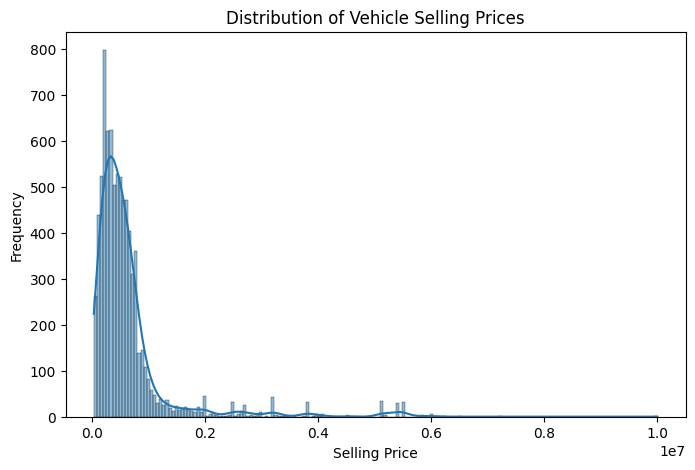

In [23]:

print("Target Variable Distribution:")

display(df['selling_price'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df['selling_price'], kde=True)
plt.title("Distribution of Vehicle Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()


In [24]:

# Check dataset size before removing duplicates
print("Before Removing Duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Check dataset size after removing duplicates
print("After Removing Duplicates:", df.shape)

print("\nTotal Duplicate Rows Remaining:", df.duplicated().sum())


Before Removing Duplicates: (8128, 13)
After Removing Duplicates: (6926, 13)

Total Duplicate Rows Remaining: 0


In [25]:

# Extract Vehicle Brand
df['brand'] = df['name'].str.split().str[0]

# Convert Mileage to Numeric
df['mileage'] = pd.to_numeric(
    df['mileage'].str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Convert Engine to Numeric
df['engine'] = pd.to_numeric(
    df['engine'].str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Convert Max Power to Numeric
df['max_power'] = pd.to_numeric(
    df['max_power'].str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Remove Torque Column
df = df.drop(columns=['torque'])

# Remove Original Name Column
df = df.drop(columns=['name'])

print("Feature Engineering Completed!")

print("\nUpdated Dataset:")
display(df.head())

print("\nUpdated Data Types:")
print(df.dtypes)


Feature Engineering Completed!

Updated Dataset:


,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,Maruti
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,Skoda
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,Honda
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,Hyundai
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,Maruti



Updated Data Types:
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
seats            float64
brand             object
dtype: object


In [26]:

# Separate Numerical and Categorical Columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Fill Numerical Missing Values with Median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill Categorical Missing Values with Mode
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Check Missing Values Again
print("Missing Values After Handling:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values After Handling:
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
brand            0
dtype: int64

Total Missing Values: 0


In [27]:

print("Final Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:", df.isnull().sum().sum())

print("\nFinal Dataset Preview:")
display(df.head())


Final Dataset Shape: (6926, 12)

Duplicate Rows: 19

Missing Values: 0

Final Dataset Preview:


,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,Maruti
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,Skoda
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,Honda
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,Hyundai
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,Maruti


In [28]:

# Remove Duplicates Again After Missing Value Imputation

df = df.drop_duplicates().reset_index(drop=True)

print("Final Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())
print("Remaining Missing Values:", df.isnull().sum().sum())

display(df.head())


Final Dataset Shape: (6907, 12)
Remaining Duplicates: 0
Remaining Missing Values: 0


,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,Maruti
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,Skoda
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,Honda
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,Hyundai
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,Maruti


In [29]:

# Check Unique Values in Categorical Columns

categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print("Unique Values:", df[col].nunique())
    print(df[col].value_counts().head(10))



fuel:
Unique Values: 4
fuel
Diesel    3747
Petrol    3066
CNG         56
LPG         38
Name: count, dtype: int64

seller_type:
Unique Values: 3
seller_type
Individual          6199
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

transmission:
Unique Values: 2
transmission
Manual       6323
Automatic     584
Name: count, dtype: int64

owner:
Unique Values: 5
owner
First Owner             4226
Second Owner            1971
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

brand:
Unique Values: 32
brand
Maruti        2158
Hyundai       1263
Mahindra       719
Tata           646
Honda          362
Ford           360
Toyota         356
Chevrolet      216
Renault        205
Volkswagen     174
Name: count, dtype: int64


In [30]:

# Separate Features and Target Variable

X = df.drop('selling_price', axis=1)
y = df['selling_price']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Variable: selling_price")


Features Shape: (6907, 11)
Target Shape: (6907,)

Feature Columns:
['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'brand']

Target Variable: selling_price


In [31]:

# Select Relevant Features

selected_features = [
    'year',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'mileage',
    'engine',
    'max_power',
    'seats',
    'brand'
]

X = X[selected_features]

print("Selected Features:", len(selected_features))
print("\nSelected Feature Names:")
print(X.columns.tolist())

print("\nFeature Selection Completed!")


Selected Features: 11

Selected Feature Names:
['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'brand']

Feature Selection Completed!


In [32]:

# Identify Numerical and Categorical Features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

Categorical Features:
['fuel', 'seller_type', 'transmission', 'owner', 'brand']


In [33]:

from sklearn.model_selection import train_test_split

# Split Dataset into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (5525, 11)
Testing Features Shape: (1382, 11)
Training Target Shape: (5525,)
Testing Target Shape: (1382,)


In [34]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Create Preprocessing Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit on Training Data and Transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform Testing Data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing Completed!")

print("\nTraining Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Preprocessing Completed!

Training Data Shape: (5525, 50)
Testing Data Shape: (1382, 50)


In [35]:

# Convert Processed Training Data to DataFrame
feature_names = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names
)

print("Scaled Numerical Features Summary:")
display(X_train_df.iloc[:, :len(numerical_features)].describe().round(2))


Scaled Numerical Features Summary:


,num__year,num__km_driven,num__mileage,num__engine,num__max_power,num__seats
count,5525.00,5525.00,5525.00,5525.00,5525.00,5525.00
mean,0.00,0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-7.46,-1.22,-4.90,-1.64,-2.78,-3.51
25%,-0.59,-0.57,-0.63,-0.47,-0.62,-0.44
50%,0.14,-0.08,-0.00,-0.36,-0.19,-0.44
75%,0.88,0.41,0.73,0.15,0.36,-0.44
max,1.62,37.31,5.68,4.47,9.90,8.78


In [36]:

# Import Required Libraries

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd
import time

# Convert Sparse Matrix to Dense Array if Required

X_train_model = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_model = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

# Define Machine Learning Models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Train and Evaluate Models

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    model.fit(X_train_model, y_train)

    training_time = time.time() - start_time

    predictions = model.predict(X_test_model)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2,
        "Training Time (Seconds)": training_time
    })

    trained_models[name] = model

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

# Display Model Comparison

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison Results:")

display(results_df.round(4))



Training Linear Regression...
MAE: 131444.12
RMSE: 251712.52
R2 Score: 0.7136

Training Decision Tree...
MAE: 93978.12
RMSE: 165900.45
R2 Score: 0.8756

Training Random Forest...
MAE: 73243.52
RMSE: 130338.3
R2 Score: 0.9232

Training Gradient Boosting...
MAE: 82769.59
RMSE: 142433.61
R2 Score: 0.9083

Model Comparison Results:


,Model,MAE,RMSE,R2 Score,Training Time (Seconds)
0,Random Forest,73243.5242,130338.2963,0.9232,2.5254
1,Gradient Boosting,82769.5889,142433.6068,0.9083,0.9405
2,Decision Tree,93978.1167,165900.4527,0.8756,0.0690
3,Linear Regression,131444.1151,251712.5226,0.7136,0.0139


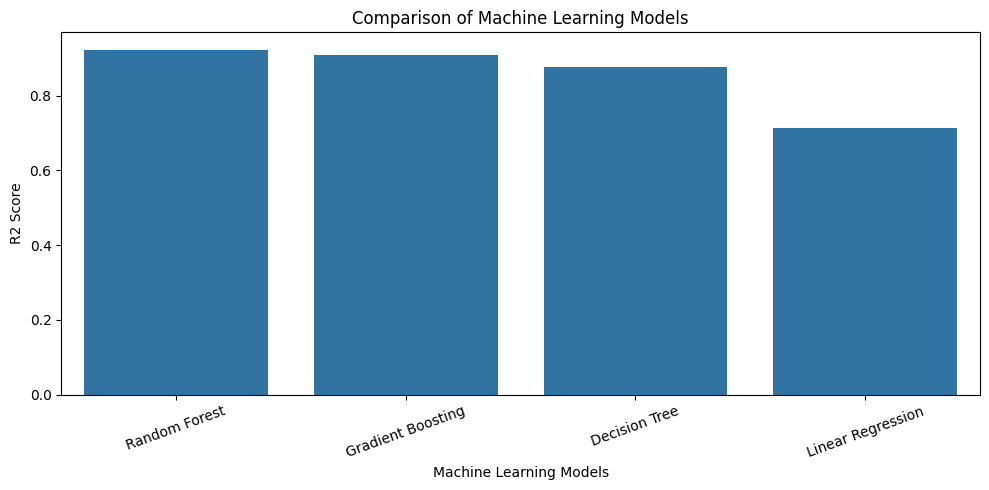

In [37]:

# Compare Model Performance

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [41]:

# Import Required Libraries

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import pandas as pd
import numpy as np

# Reload Original Dataset
raw_df = pd.read_csv('/content/Car details v3.csv')

# Remove Original Duplicate Rows
raw_df = raw_df.drop_duplicates().reset_index(drop=True)

# Feature Engineering
raw_df['brand'] = raw_df['name'].str.split().str[0]

for col in ['mileage', 'engine', 'max_power']:
    raw_df[col] = pd.to_numeric(
        raw_df[col].astype(str).str.extract(r'(\d+\.?\d*)')[0],
        errors='coerce'
    )

# Remove Unnecessary Columns
raw_df = raw_df.drop(columns=['name', 'torque'])

# Separate Features and Target
X = raw_df.drop(columns=['selling_price'])
y = raw_df['selling_price']

# Identify Feature Types
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Numerical Preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine Preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Leakage-Free Preprocessing Setup Completed!")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)


Leakage-Free Preprocessing Setup Completed!
Training Records: 5540
Testing Records: 1386
Numerical Features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Categorical Features: ['fuel', 'seller_type', 'transmission', 'owner', 'brand']


In [42]:

# Define Models with Complete Preprocessing Pipelines

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

results_df = pd.DataFrame(results).sort_values(
    by='R2 Score', ascending=False
).reset_index(drop=True)

print("\nUpdated Model Comparison:")
display(results_df.round(4))



Training Linear Regression...
MAE: 133098.56
RMSE: 261924.59
R2 Score: 0.6872

Training Decision Tree...
MAE: 93950.9
RMSE: 171722.55
R2 Score: 0.8655

Training Random Forest...
MAE: 73510.02
RMSE: 130176.29
R2 Score: 0.9227

Training Gradient Boosting...
MAE: 82874.18
RMSE: 131431.44
R2 Score: 0.9212

Updated Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Random Forest,73510.0171,130176.2926,0.9227
1,Gradient Boosting,82874.1826,131431.4369,0.9212
2,Decision Tree,93950.9042,171722.5535,0.8655
3,Linear Regression,133098.5576,261924.5867,0.6872


In [43]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_dist = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Random Forest Hyperparameter Tuning...")

random_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-random_search.best_score_, 2))

Starting Random Forest Hyperparameter Tuning...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 20}

Best Cross-Validation RMSE:
176411.47


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Get the best model from RandomizedSearchCV
tuned_model = random_search.best_estimator_

# Predict on test data
tuned_predictions = tuned_model.predict(X_test)

# Evaluate tuned model
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE:", round(tuned_mae, 2))
print("RMSE:", round(tuned_rmse, 2))
print("R2 Score:", round(tuned_r2, 4))

# Compare baseline and tuned Random Forest
baseline_rf = results_df[results_df['Model'] == 'Random Forest'].iloc[0]

comparison = pd.DataFrame([
    {
        'Model': 'Baseline Random Forest',
        'MAE': baseline_rf['MAE'],
        'RMSE': baseline_rf['RMSE'],
        'R2 Score': baseline_rf['R2 Score']
    },
    {
        'Model': 'Tuned Random Forest',
        'MAE': tuned_mae,
        'RMSE': tuned_rmse,
        'R2 Score': tuned_r2
    }
])

display(comparison.round(4))

Tuned Random Forest Performance
--------------------------------
MAE: 73304.78
RMSE: 130264.13
R2 Score: 0.9226


,Model,MAE,RMSE,R2 Score
0,Baseline Random Forest,73510.0171,130176.2926,0.9227
1,Tuned Random Forest,73304.7778,130264.1309,0.9226


In [45]:
if tuned_rmse < baseline_rf['RMSE']:
    best_pipeline = tuned_model
    best_model_name = "Tuned Random Forest"
    best_mae = tuned_mae
    best_rmse = tuned_rmse
    best_r2 = tuned_r2
else:
    best_pipeline = trained_models["Random Forest"]
    best_model_name = "Baseline Random Forest"
    best_mae = baseline_rf['MAE']
    best_rmse = baseline_rf['RMSE']
    best_r2 = baseline_rf['R2 Score']

print("FINAL SELECTED MODEL")
print("--------------------")
print("Model:", best_model_name)
print("MAE:", round(best_mae, 2))
print("RMSE:", round(best_rmse, 2))
print("R2 Score:", round(best_r2, 4))

FINAL SELECTED MODEL
--------------------
Model: Baseline Random Forest
MAE: 73510.02
RMSE: 130176.29
R2 Score: 0.9227


Top 15 Important Features:


,Feature,Importance
4,num__max_power,0.601118
0,num__year,0.229738
1,num__km_driven,0.044973
2,num__mileage,0.037968
3,num__engine,0.023298
5,num__seats,0.008799
39,cat__brand_Mercedes-Benz,0.005995
47,cat__brand_Toyota,0.005426
46,cat__brand_Tata,0.004110
22,cat__brand_BMW,0.004089


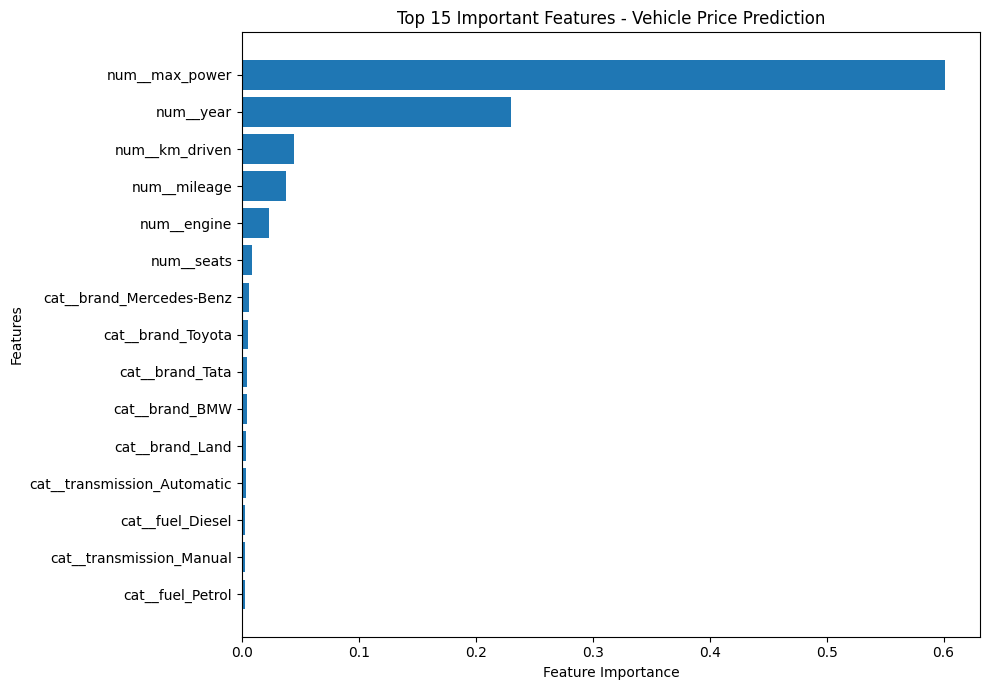

In [46]:
import matplotlib.pyplot as plt
import pandas as pd

final_rf = best_pipeline.named_steps['model']

feature_names = best_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': final_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

plt.figure(figsize=(10, 7))

top_features = importance_df.head(15).sort_values(
    by='Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Vehicle Price Prediction")
plt.tight_layout()
plt.show()

In [47]:
import joblib

model_path = '/content/best_vehicle_price_model.joblib'

joblib.dump(best_pipeline, model_path)

print("Best model saved successfully!")
print("File:", model_path)

Best model saved successfully!
File: /content/best_vehicle_price_model.joblib


In [48]:
loaded_model = joblib.load(
    '/content/best_vehicle_price_model.joblib'
)

sample_prediction = loaded_model.predict(X_test.iloc[:5])

print("Sample Actual Prices:")
print(y_test.iloc[:5].values)

print("\nSample Predicted Prices:")
print(np.round(sample_prediction, 2))

Sample Actual Prices:
[ 550000 1225000  850000   80000  825000]

Sample Predicted Prices:
[ 693649.97 1065436.47  840276.67  151695.22  694280.  ]


In [49]:
plt.savefig(
    '/content/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [50]:
results_df.to_csv(
    '/content/model_comparison.csv',
    index=False
)

comparison.to_csv(
    '/content/random_forest_comparison.csv',
    index=False
)

importance_df.to_csv(
    '/content/feature_importance.csv',
    index=False
)

print("All result CSV files saved successfully!")

All result CSV files saved successfully!
